In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import xarray as xr

df = pd.read_csv("/storage/mathelierarea/processed/eirikhoy/action_var/data/eirik/ism_files 2/cancer_breast_ism/data/BRCA2_ism_breast.csv")
df[['chrom', 'pos', 'mut']] = df['SNP'].str.split('_', expand=True)
df['pos'] = df['pos'].astype(int)

positions = sorted(df['pos'].unique())
non_cell_cols = ['SNP', 'macro_mean', 'chrom', 'pos', 'mut']

cell_types = [i for i in df.columns if i not in non_cell_cols]

nucleotides = ['A', 'C', 'G', 'T']

data = np.full((len(positions), len(nucleotides), len(cell_types)), np.nan)

da = xr.DataArray(
    data,
    dims = ['pos', 'nuc', 'cell_type'],
    coords={'pos': positions, 'nuc': nucleotides, 'cell_type': cell_types}
)


# fill in array
for _, row in df.iterrows():
    da.loc[dict(pos=row['pos'], nuc=row['mut'])] = row[cell_types].values



In [2]:
len(da.pos)

39984

13_32889647_A_C



In [3]:
13//2

6

In [12]:
import logomaker 
import matplotlib.pyplot as plt

window_size = 50


slice_df = da.sel(cell_type='CD8_activated').to_pandas()
slice_df = slice_df.fillna(0)

mutation = 32889647
start = mutation-(window_size//2)

window = slice_df.iloc[start:start + window_size]
logo = logomaker.Logo(
    window, 
    shade_below=0.5,
    fade_below=0.5
)

logo.ax.set_ylabel("Predicted effect")
logo.ax.set_xlabel("Position")
plt.show()


LogomakerError: df has zero rows. Needs multiple rows.

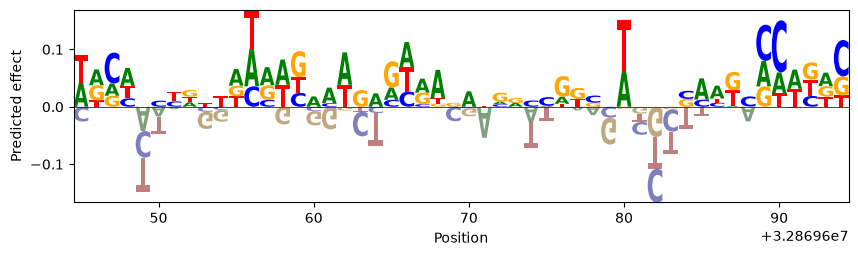

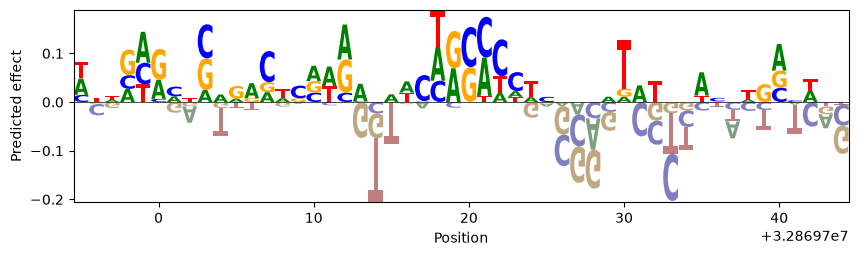

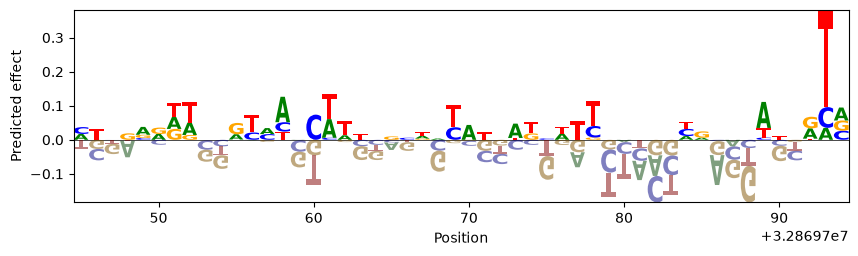

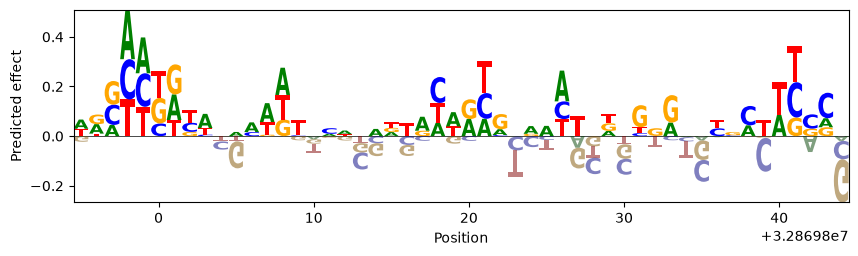

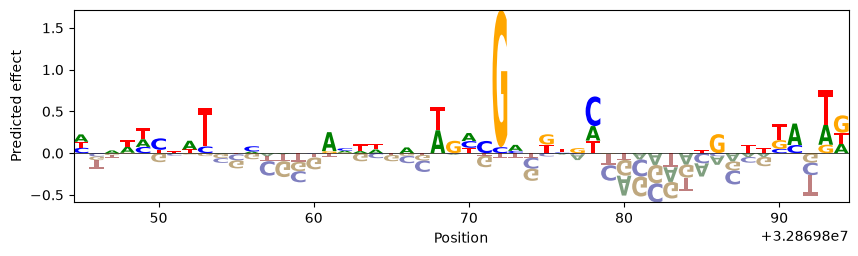

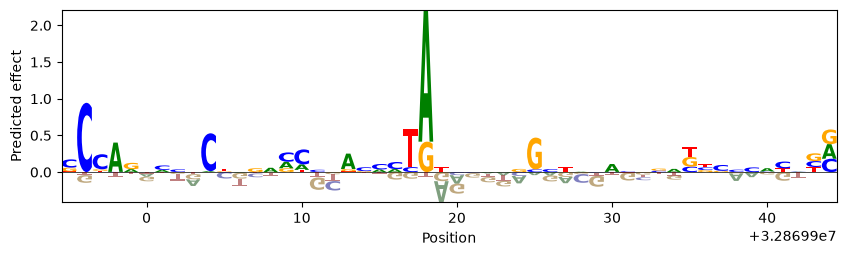

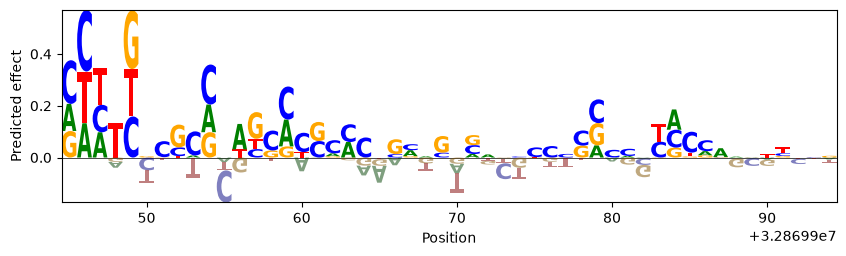

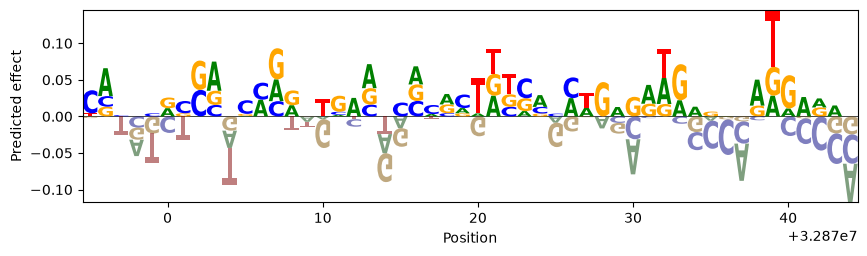

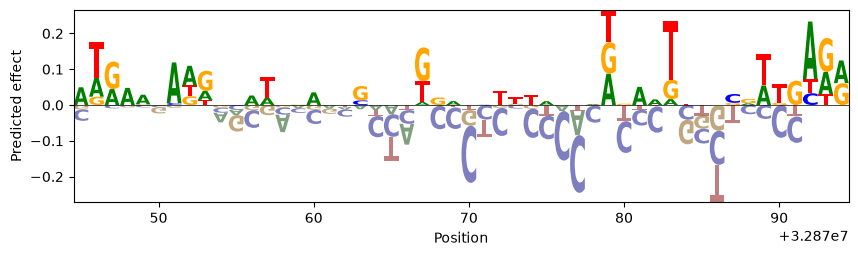

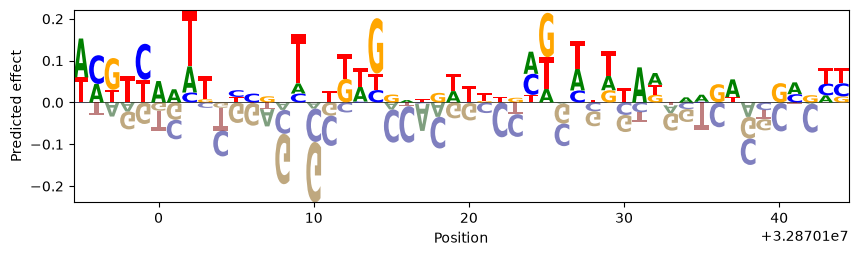

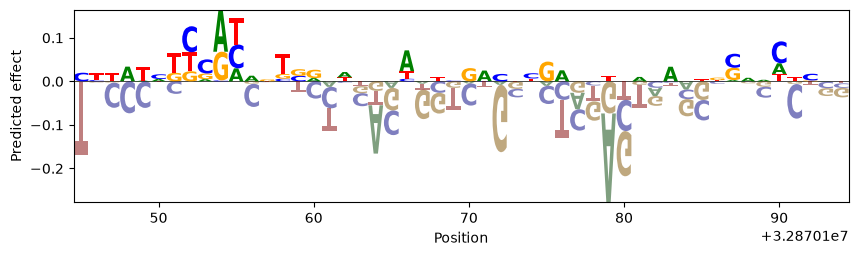

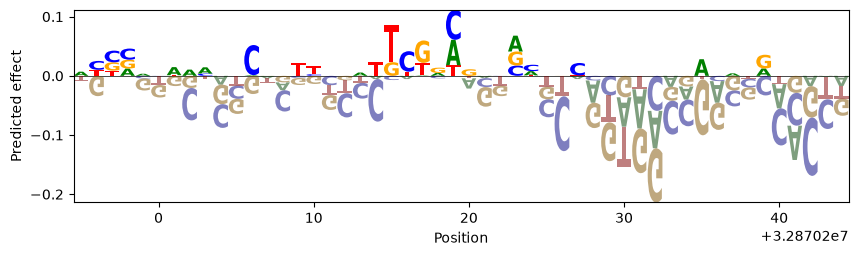

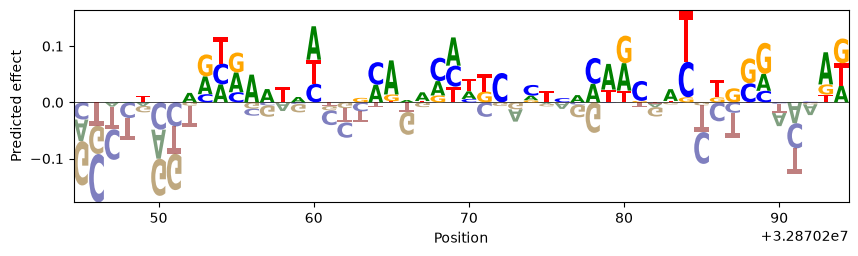

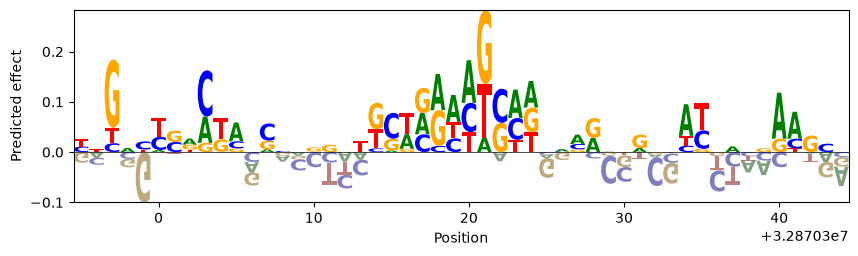

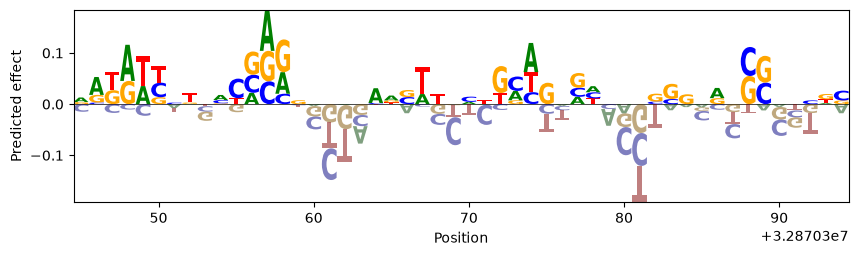

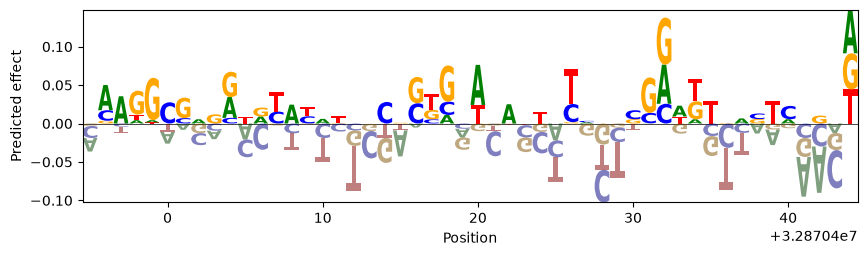

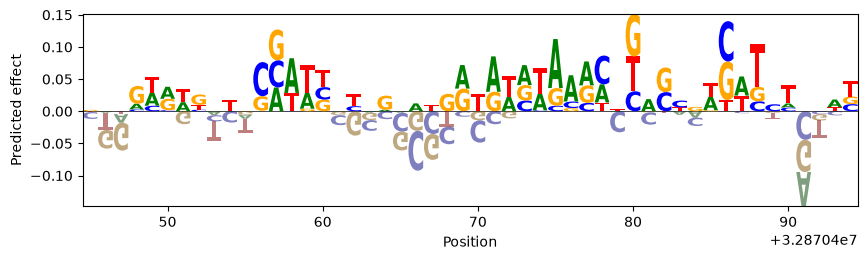

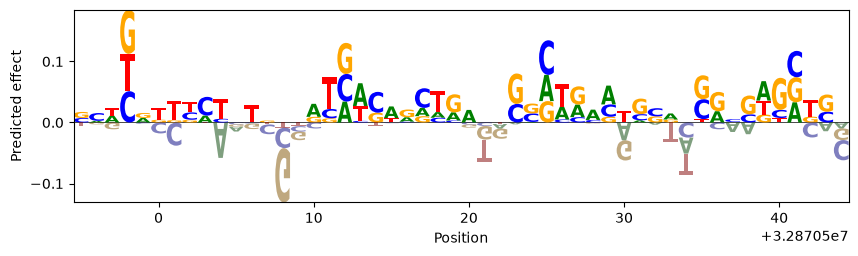

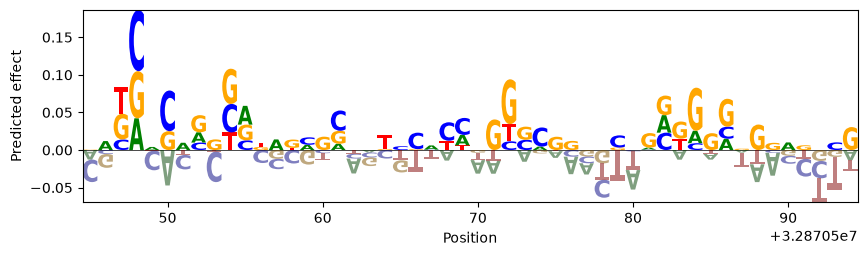

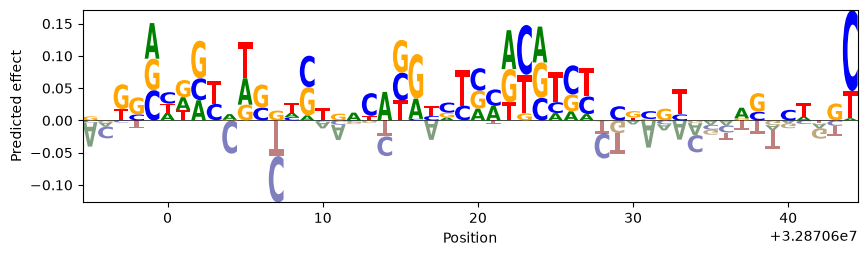

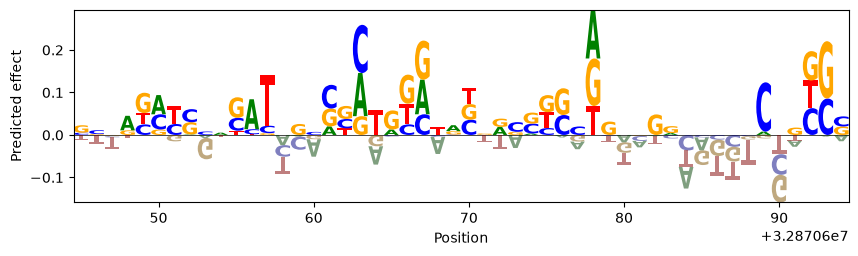

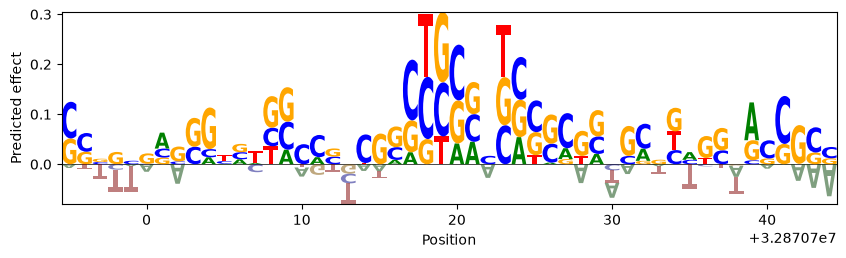

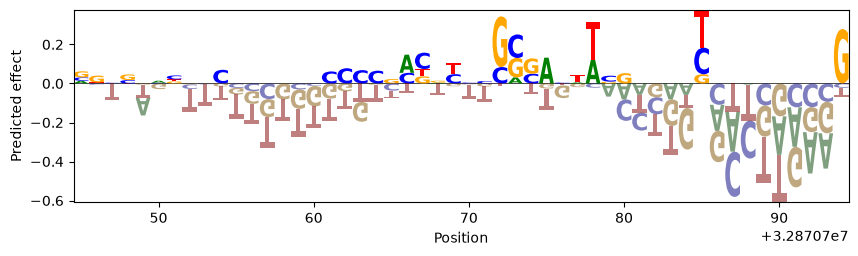

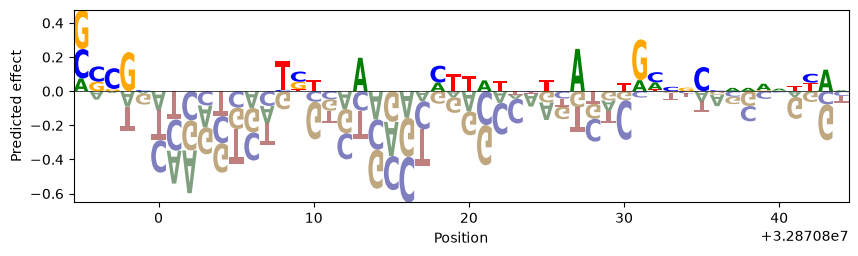

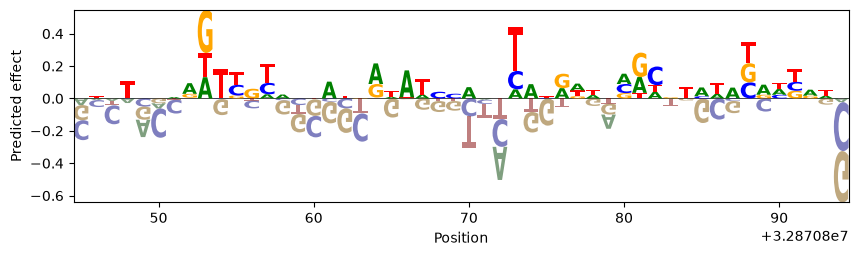

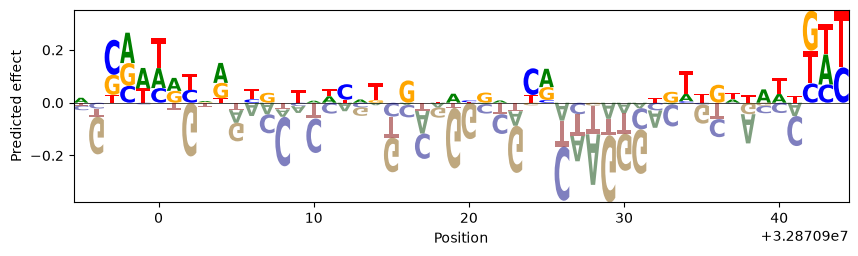

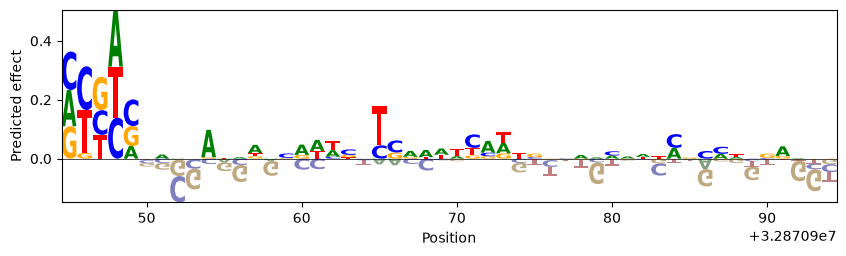

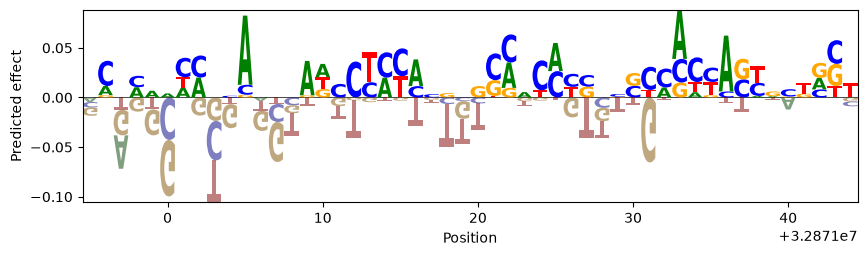

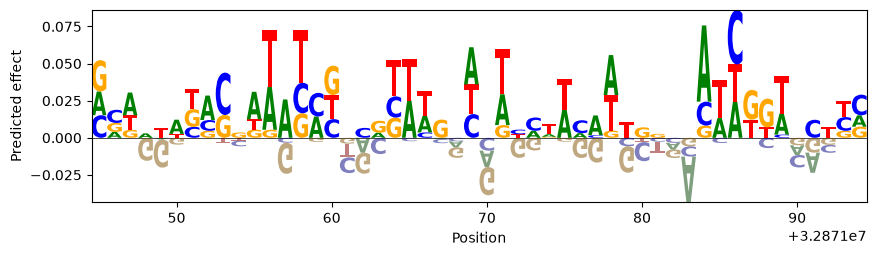

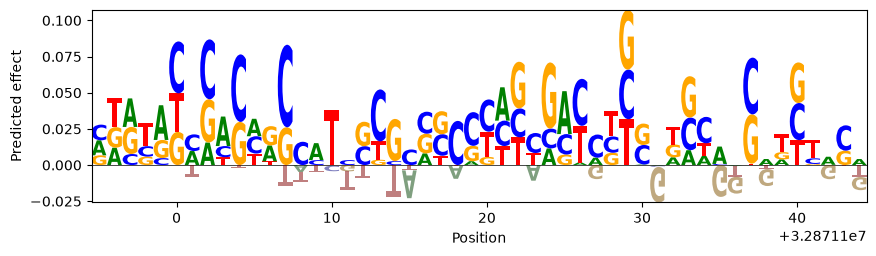

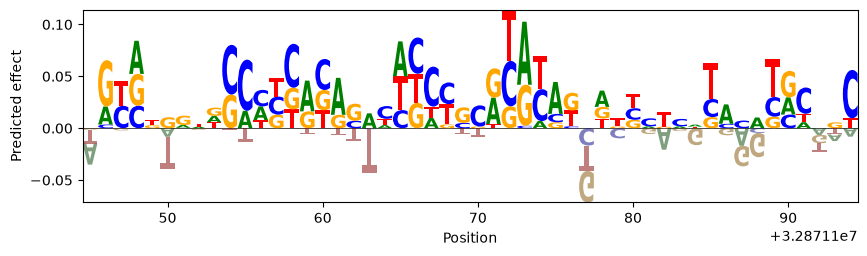

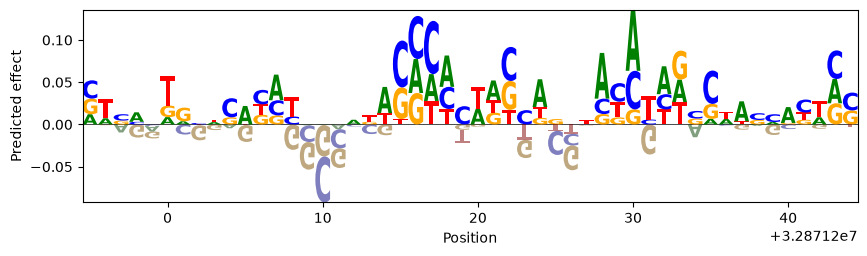

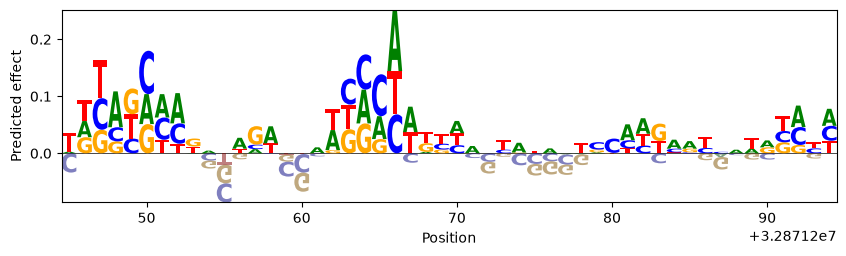

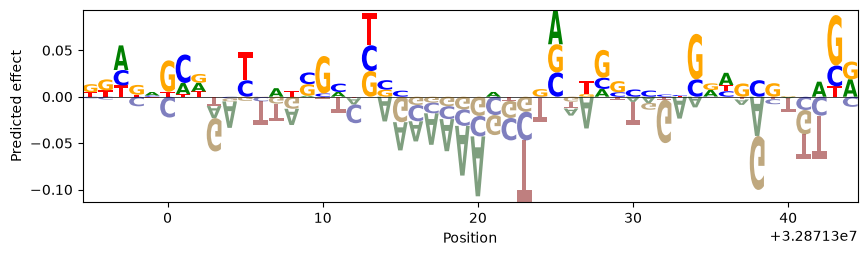

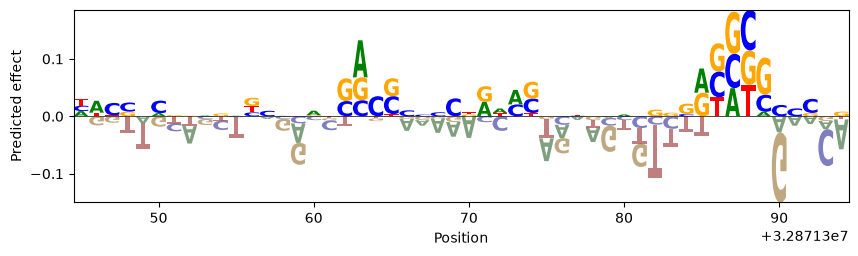

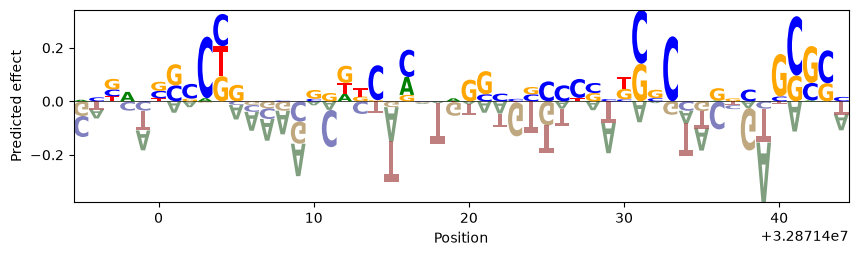

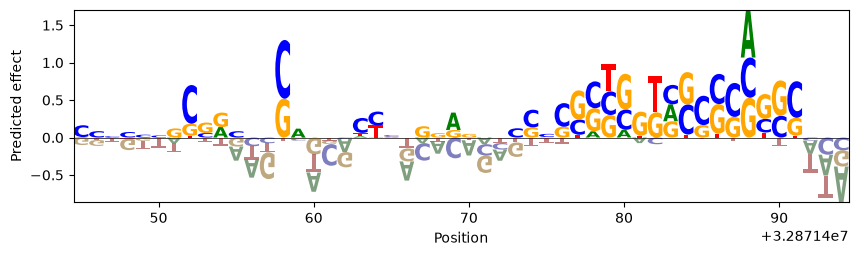

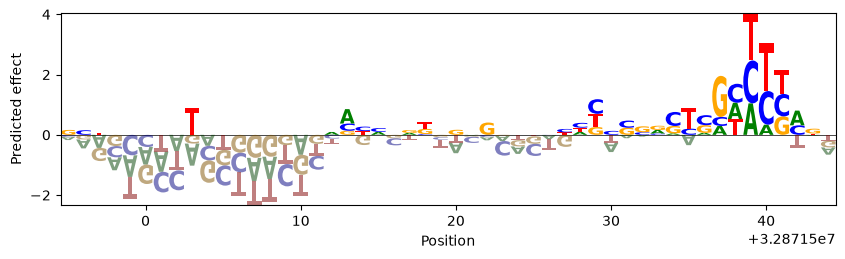

KeyboardInterrupt: 

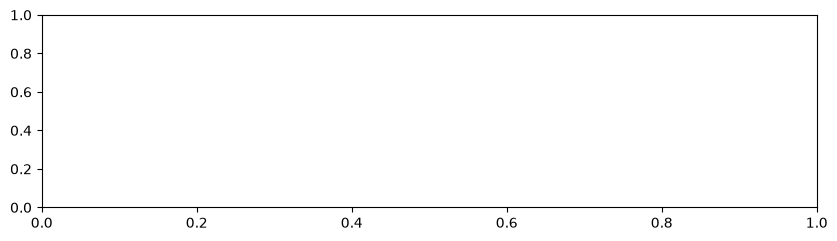

In [2]:
import logomaker
import matplotlib.pyplot as plt

window_size = 50

slice_df = da.sel(cell_type='CD8_activated').to_pandas()
slice_df = slice_df.fillna(0)

for start in range(0, len(slice_df), window_size):
    window = slice_df.iloc[start:start + window_size]

    logo = logomaker.Logo(
        window,
        shade_below=0.5,
        fade_below=0.5
    )

    logo.ax.set_ylabel("Predicted effect")
    logo.ax.set_xlabel("Position")
    plt.show()

KeyboardInterrupt: 

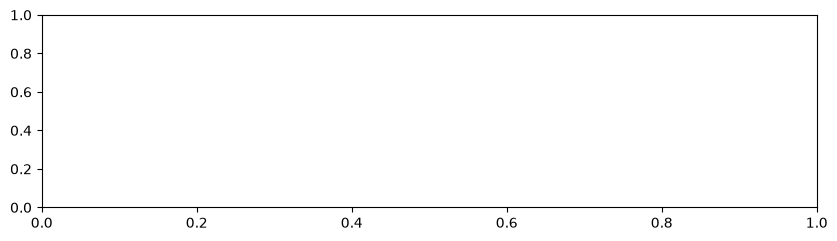

In [56]:
import logomaker
import matplotlib.pyplot as plt


slice_df = da.sel(cell_type='CD8_activated').to_pandas()
slice_df = slice_df.fillna(0)

logo = logomaker.Logo(slice_df, shade_below=0.5, fade_below=0.5)
logo.ax.set_ylabel("Predicted effect")
logo.ax.set_xlabel("Position")
plt.show()